In [4]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# CONNECTION
SERVER   = "localhost\\SQLEXPRESS"
DATABASE = "retail_sales"
engine   = create_engine(
    f"mssql+pyodbc://{SERVER}/{DATABASE}"
    f"?driver=ODBC+Driver+17+for+SQL+Server"
    f"&trusted_connection=yes"
)

# LOAD TABLES
transactions     = pd.read_sql("SELECT * FROM transactions", engine)
customer_summary = pd.read_sql("SELECT * FROM customer_summary", engine)
monthly_summary  = pd.read_sql("SELECT * FROM monthly_summary", engine)
response         = pd.read_sql("SELECT * FROM customer_response", engine)

# Fix date column
transactions["trans_date"] = pd.to_datetime(transactions["trans_date"])

print("Data loaded successfully.")
print(f"  transactions     : {len(transactions):,} rows")
print(f"  customer_summary : {len(customer_summary):,} rows")
print(f"  monthly_summary  : {len(monthly_summary):,} rows")
print(f"  response         : {len(response):,} rows")

Data loaded successfully.
  transactions     : 125,000 rows
  customer_summary : 6,889 rows
  monthly_summary  : 47 rows
  response         : 6,884 rows


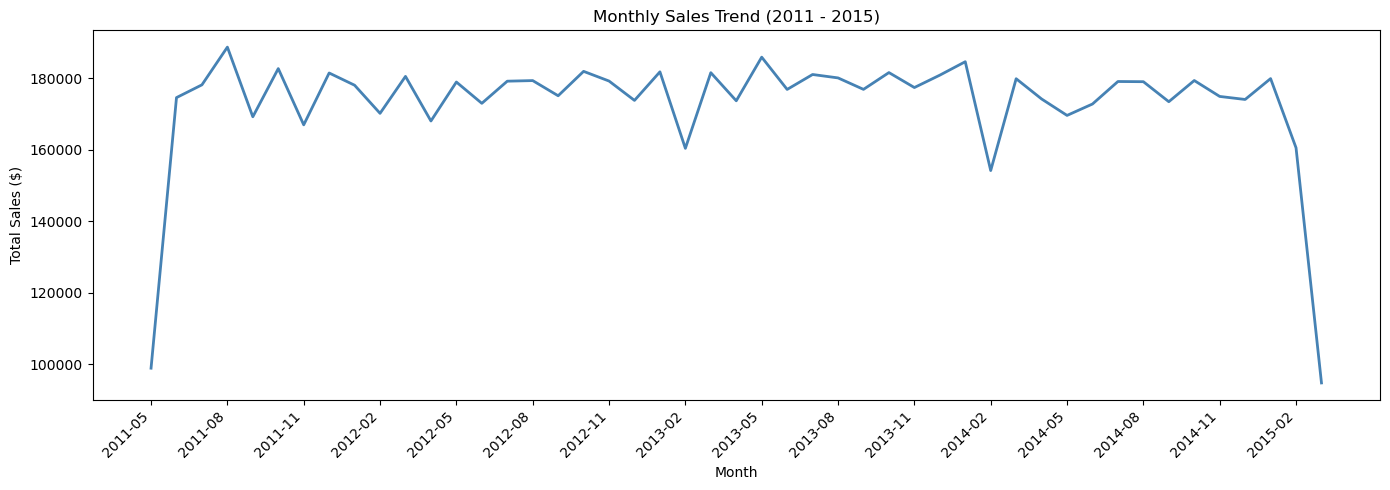

Chart saved.


In [2]:
# CELL 2: MONTHLY SALES TREND

monthly_summary["period"] = (
    monthly_summary["trans_year"].astype(str) + "-" +
    monthly_summary["trans_month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))
plt.plot(monthly_summary["period"], monthly_summary["total_sales"], color="steelblue", linewidth=2)
plt.xticks(monthly_summary["period"][::3], rotation=45, ha="right")
plt.title("Monthly Sales Trend (2011 - 2015)")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.savefig(r"C:\Users\Asus\Downloads\archive\monthly_sales_trend.png", dpi=150)
plt.show()
print("Chart saved.")

Yearly Sales Summary:
 trans_year  total_sales  total_orders
       2011    1340339.0         20658
       2012    2116599.0         32541
       2013    2137368.0         32904
       2014    2094508.0         32226
       2015     435175.0          6671


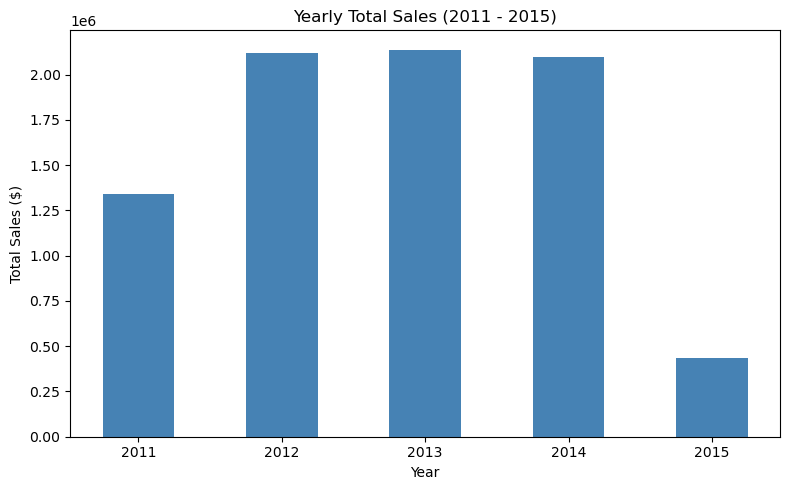

Chart saved.


In [3]:
# CELL 3: YEARLY SALES COMPARISON

yearly_summary = transactions.groupby("trans_year").agg(
    total_sales  = ("tran_amount", "sum"),
    total_orders = ("tran_amount", "count")
).reset_index()

yearly_summary["total_sales"] = yearly_summary["total_sales"].round(2)

print("Yearly Sales Summary:")
print(yearly_summary.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(yearly_summary["trans_year"].astype(str), yearly_summary["total_sales"], color="steelblue", width=0.5)
plt.title("Yearly Total Sales (2011 - 2015)")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.savefig(r"C:\Users\Asus\Downloads\archive\yearly_sales.png", dpi=150)
plt.show()
print("Chart saved.")

Top 10 Customers by Total Spend:
customer_id  total_spend  transaction_count  avg_transaction
     CS4424         2933                 39            75.21
     CS4320         2647                 38            69.66
     CS5752         2612                 33            79.15
     CS4660         2527                 33            76.58
     CS3799         2513                 36            69.81
     CS5109         2506                 35            71.60
     CS4074         2462                 34            72.41
     CS3805         2453                 35            70.09
     CS4608         2449                 32            76.53
     CS5555         2439                 31            78.68


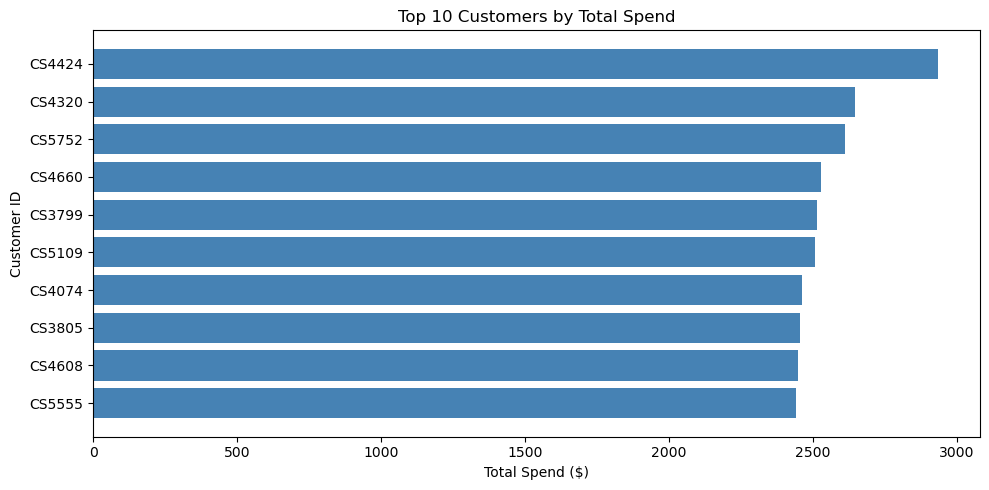

Chart saved.


In [5]:
# CELL 4: TOP 10 CUSTOMERS BY SPEND

top10 = customer_summary.nlargest(10, "total_spend")[["customer_id", "total_spend", "transaction_count", "avg_transaction"]]

print("Top 10 Customers by Total Spend:")
print(top10.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(top10["customer_id"], top10["total_spend"], color="steelblue")
plt.title("Top 10 Customers by Total Spend")
plt.xlabel("Total Spend ($)")
plt.ylabel("Customer ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"C:\Users\Asus\Downloads\archive\top10_customers.png", dpi=150)
plt.show()
print("Chart saved.")

Customer Response Overview:
  Total customers      : 6,884
  Responded (1)        : 647
  Did not respond (0)  : 6,237
  Response rate        : 9.40%

Average Spend by Response Group:
          total_spend  avg_transaction  transaction_count
response                                                 
0             1149.08            62.52              17.82
1             1476.89            68.58              21.39


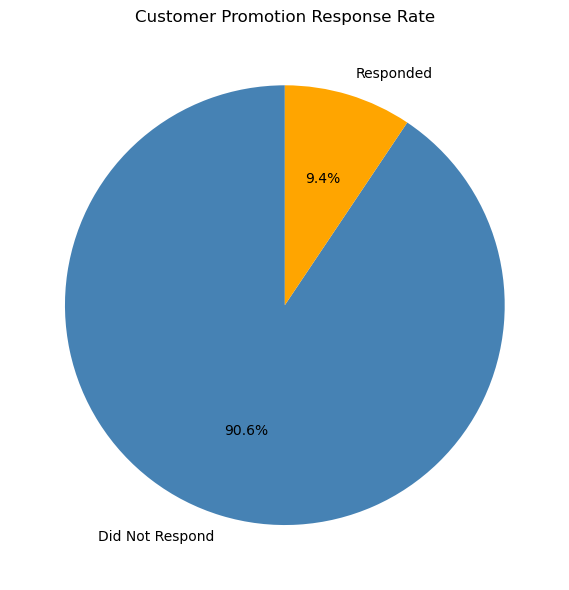

Chart saved.


In [6]:
# CELL 5: CUSTOMER RESPONSE ANALYSIS

# Merge customer_summary with response
merged = customer_summary.merge(response, on="customer_id", how="inner")

# Response rate overview
response_counts = merged["response"].value_counts()
response_rate   = (merged["response"].sum() / len(merged)) * 100

print("Customer Response Overview:")
print(f"  Total customers      : {len(merged):,}")
print(f"  Responded (1)        : {response_counts.get(1, 0):,}")
print(f"  Did not respond (0)  : {response_counts.get(0, 0):,}")
print(f"  Response rate        : {response_rate:.2f}%")

# Compare spend between responders and non-responders
print("\nAverage Spend by Response Group:")
print(merged.groupby("response")[["total_spend", "avg_transaction", "transaction_count"]].mean().round(2))

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    response_counts,
    labels=["Did Not Respond", "Responded"],
    autopct="%1.1f%%",
    colors=["steelblue", "orange"],
    startangle=90
)
plt.title("Customer Promotion Response Rate")
plt.tight_layout()
plt.savefig(r"C:\Users\Asus\Downloads\archive\response_rate.png", dpi=150)
plt.show()
print("Chart saved.")

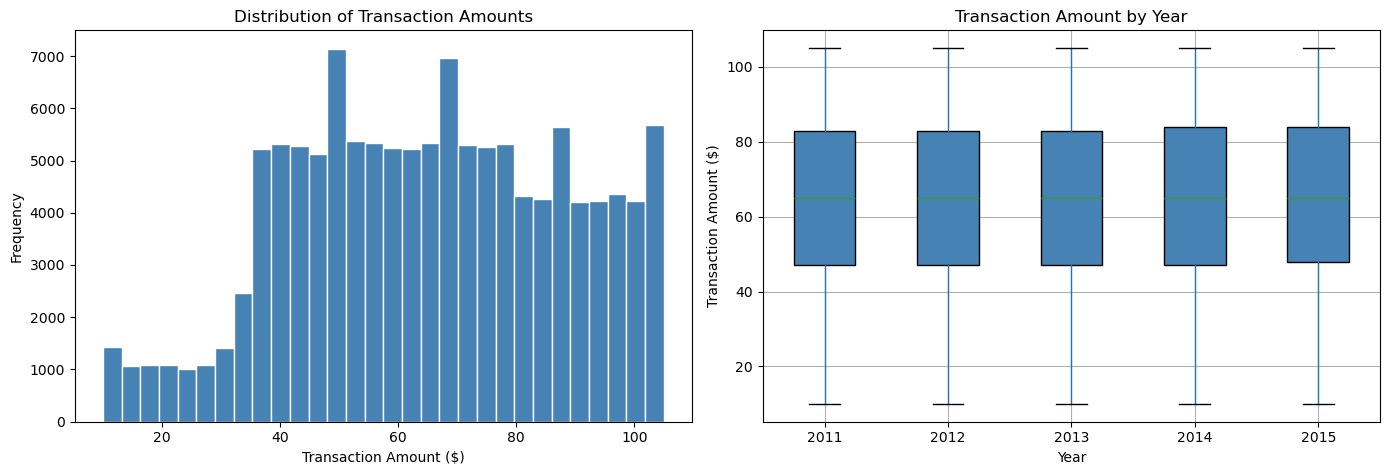

Chart saved.


In [7]:
# CELL 6: TRANSACTION AMOUNT DISTRIBUTION

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(transactions["tran_amount"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Transaction Amounts")
axes[0].set_xlabel("Transaction Amount ($)")
axes[0].set_ylabel("Frequency")

# Boxplot by year
transactions.boxplot(
    column="tran_amount",
    by="trans_year",
    ax=axes[1],
    patch_artist=True,
    boxprops=dict(facecolor="steelblue")
)
axes[1].set_title("Transaction Amount by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Transaction Amount ($)")
plt.suptitle("")

plt.tight_layout()
plt.savefig(r"C:\Users\Asus\Downloads\archive\transaction_distribution.png", dpi=150)
plt.show()
print("Chart saved.")

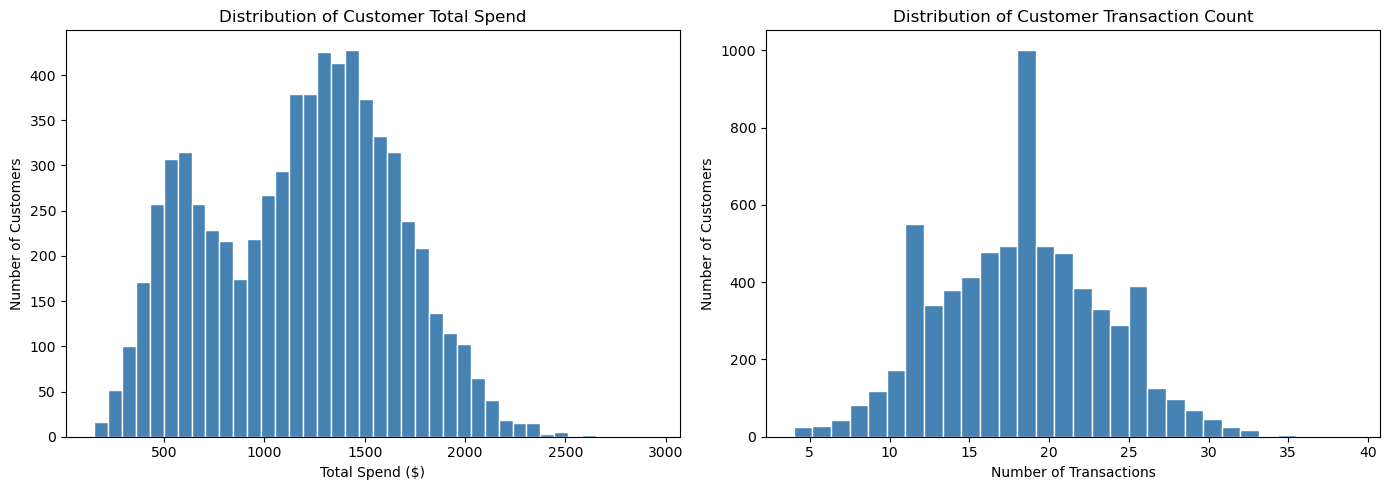

Customer Spend Summary:
       total_spend  transaction_count  avg_transaction  lifespan_days
count      6889.00            6889.00          6889.00        6889.00
mean       1179.27              18.14            63.09        1240.89
std         465.83               5.19            12.43         122.86
min         149.00               4.00            26.70         152.00
25%         781.00              14.00            52.67        1188.00
50%        1227.00              18.00            67.70        1270.00
75%        1520.00              22.00            72.00        1326.00
max        2933.00              39.00            87.40        1400.00


In [8]:
# CELL 7: CUSTOMER SPEND DISTRIBUTION

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of total spend per customer
axes[0].hist(customer_summary["total_spend"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Customer Total Spend")
axes[0].set_xlabel("Total Spend ($)")
axes[0].set_ylabel("Number of Customers")

# Transaction count distribution
axes[1].hist(customer_summary["transaction_count"], bins=30, color="steelblue", edgecolor="white")
axes[1].set_title("Distribution of Customer Transaction Count")
axes[1].set_xlabel("Number of Transactions")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(r"C:\Users\Asus\Downloads\archive\customer_spend_distribution.png", dpi=150)
plt.show()

# Summary statistics
print("Customer Spend Summary:")
print(customer_summary[["total_spend", "transaction_count", "avg_transaction", "lifespan_days"]].describe().round(2))